# E3 — TabPFN 2.5 después de fine-tuning

Se evalúa el paquete local `20261015_091524_448419`, entregado por el usuario.
Checkpoint: `tabpfn_25_finetuned.ckpt`. Cinco épocas finales, 119 tensores de pesos
modificados respecto al checkpoint oficial. Se conserva el original como referencia.
Este notebook **solo realiza inferencia**, no vuelve a optimizar pesos.

El código de evaluación está en `evaluar_tabpfn25_finetuned_e3.py` y el de carga del paquete
en `finetune_tabpfn25_e3.load_bundle`. Usar el kernel del venv compartido del proyecto.

## Integridad y protocolo

Se verifican los checksums de pesos, preprocesador y contexto; hashes de la fuente y del
script de entrenamiento; las 15 variables y el objetivo; la matriz transformada y las notas
del contexto frente a las 1309 filas de train canónico. El contexto excluye el test temporal.
La preparación es la misma del SVM: imputación, log1p en tiempos, escalado y one-hot.

Se predicen los mismos **188 estudiantes del periodo 202530**, con cuatro estimadores de
inferencia y semilla42, como TabPFN original. Se calculan RMSE, MAE, MAPE(%) y R² usando
la función del tablero, sin recortar notas predichas. Los resultados anteriores no se sobrescriben.

Las épocas se seleccionaron dentro de train con cinco folds por estudiante y se volvió a
partir del checkpoint oficial para el ajuste final con todo train. Los pesos finales ya vieron
todos esos estudiantes: **no pueden producir nuevas predicciones OOF válidas sobre train**.
La CV de selección de épocas tampoco constituye una CV externa anidada. Se compara aquí
el test temporal; obtener una nueva CV externa exigiría fine-tuning independiente dentro de
cada fit externo, incluyendo selección interna de épocas.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display
BOOK = Path.cwd() if (Path.cwd() / 'entregable3.py').exists() else Path.cwd() / 'Precalculo'
sys.path.insert(0, str(BOOK.resolve()))
from evaluar_tabpfn25_finetuned_e3 import evaluate, show, DEFAULT_BUNDLE
report = evaluate(DEFAULT_BUNDLE, force=False)
print('Paquete:', report['bundle'])
print('Épocas finales:', report['epochs_final'])
print('Inferencia:', report['inference'])
print('Filas test:', report['partition']['test_valid'])

Paquete verificado: 5 épocas finales; 119 tensores cambiaron. Contexto idéntico a train.


Reutilizando evaluación completa con procedencia verificada.


Paquete: C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\modelos_preentrenados\tabpfn_25\finetuning\20261015_091524_448419
Épocas finales: 5
Inferencia: {'n_estimators': 4, 'random_state': 42}
Filas test: 188


## Comparación en el mismo test

Cada métrica tiene su propio panel y escala. Naranja identifica el modelo ajustado,
verde el TabPFN original y azul las referencias del tablero y logicDT.
Las diferencias estadísticas se calculan respecto al modelo original y al SVM.

,Modelo,RMSE,MAE,MAPE (%),R²
8,TabPFN 2.5 original,0.898277,0.715491,27.761050,0.464223
9,TabPFN 2.5 fine-tuned,0.901370,0.722380,28.072635,0.460527
6,XGBoost,0.906274,0.728918,28.404775,0.454641
3,Ridge,0.917090,0.754511,29.572140,0.441545
4,Lasso,0.919650,0.753040,29.551967,0.438424
2,KNN,0.923270,0.754027,29.584495,0.433995
7,logicDT propio (adaptado),0.926438,0.760954,29.658839,0.430104
0,SVM lineal,0.927706,0.755443,29.664556,0.428543
5,Random Forest,0.939635,0.765847,29.732021,0.413751
1,Dummy media,1.256059,1.104467,42.314507,-0.047571


,referencia,metrica,diferencia_ajustado_menos_referencia,IC_2.5%,IC_97.5%,p_bilateral,p_Holm_dos_comparaciones,significativa_al_5%_Holm
0,TabPFN 2.5 original,RMSE,0.003093,-0.007059,0.013159,0.54892,0.54892,False
1,TabPFN 2.5 original,R²,-0.003696,-0.015229,0.009000,0.54892,0.54892,False
2,SVM lineal,RMSE,-0.026336,-0.056160,0.002756,0.08018,0.16036,False
3,SVM lineal,R²,0.031984,-0.003467,0.068926,0.08018,0.16036,False


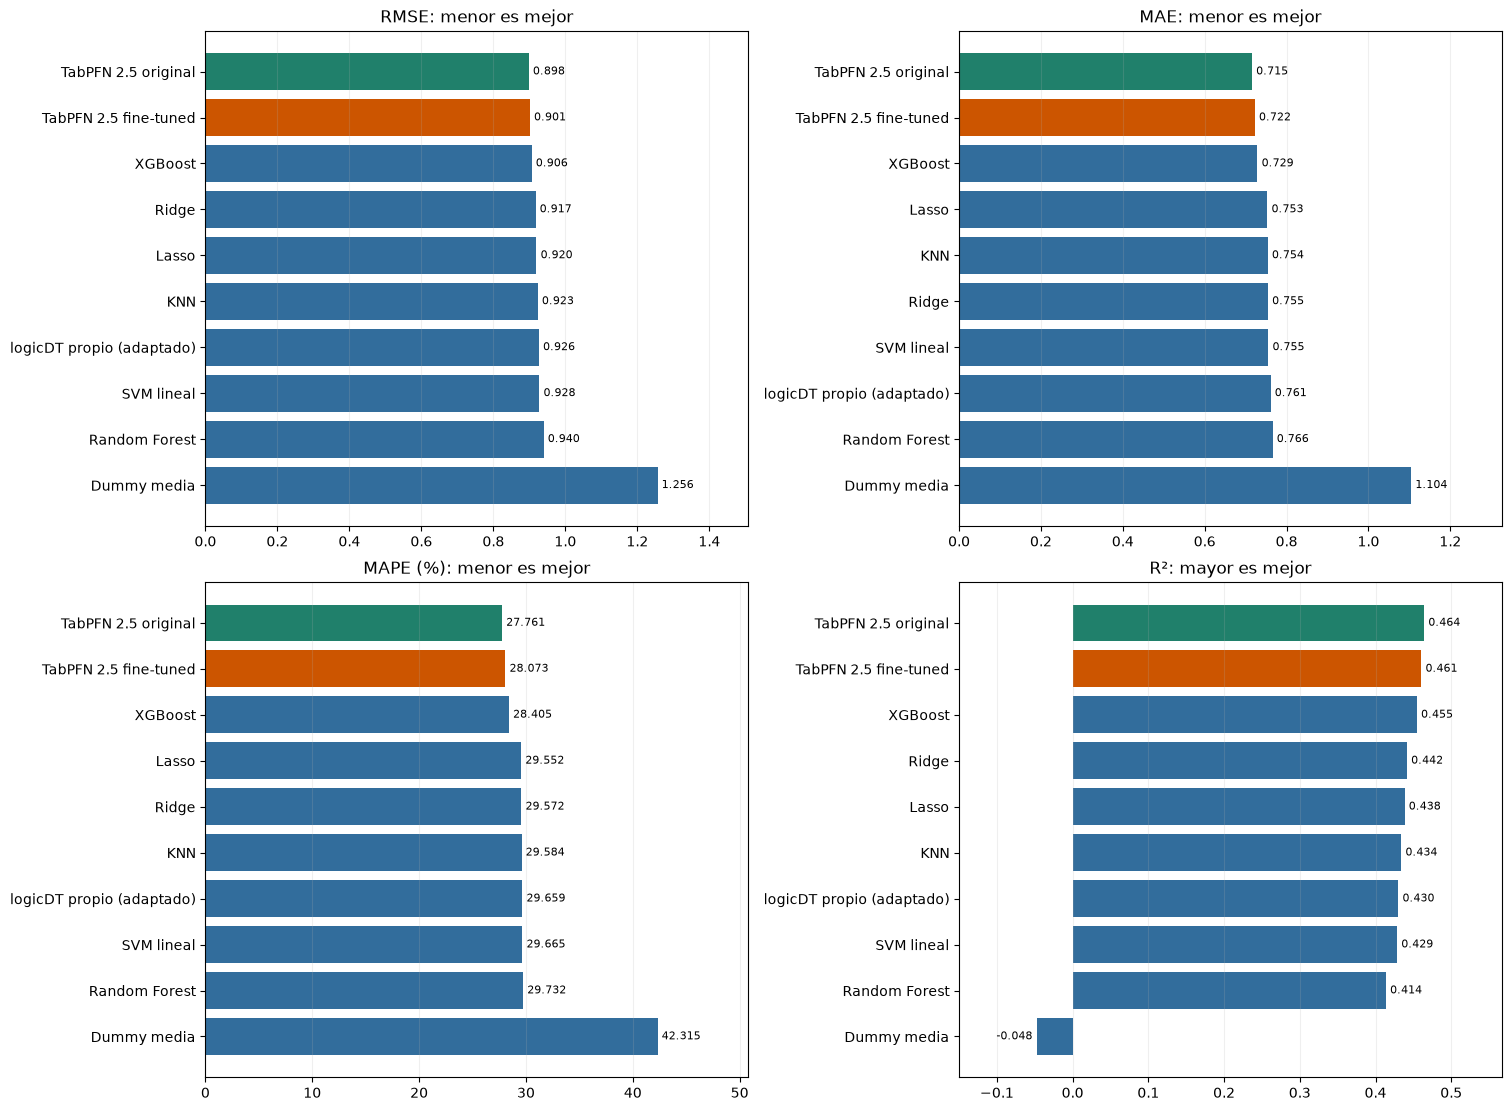

Cambio RMSE frente al original: +0.003093
Reducción relativa de RMSE: -0.344%
Cambio R² frente al original: -0.003696


In [2]:
show(report)
table = pd.DataFrame(report['comparison_test'])
new = table.loc[table.Modelo.eq(report['model'])].iloc[0]
base = table.loc[table.Modelo.eq('TabPFN 2.5 original')].iloc[0]
print(f"Cambio RMSE frente al original: {new['RMSE']-base['RMSE']:+.6f}")
print(f"Reducción relativa de RMSE: {100*(base['RMSE']-new['RMSE'])/base['RMSE']:.3f}%")
print(f"Cambio R² frente al original: {new['R²']-base['R²']:+.6f}")

## Contrastes pareados e incertidumbre

Se usa permutación pareada bilateral por estudiante (99999 permutaciones) y bootstrap
pareado por estudiante (10000 réplicas), semilla42. Los 188 estudiantes tienen una fila
cada uno. H0 supone intercambiabilidad de pérdidas cuadradas por estudiante.
La diferencia reportada es **ajustado menos referencia**: negativa favorece al ajustado
para RMSE y positiva para R². Los intervalos son IC95% percentiles sin ajuste simultáneo.

RMSE y R² dependen de la misma SSE en este test y dan el mismo contraste de permutación;
no se cuentan como evidencias independientes. Se aplica **Holm** a los dos pares de modelos
(ajustado vs original y ajustado vs SVM), a alpha .05. Se muestran p-valores crudos y ajustados.

La inferencia es exploratoria y condicional a estos modelos y este periodo: el test se ha
inspeccionado en etapas previas y no incluye variabilidad por reentrenar. No rechazar H0 no
demuestra equivalencia. Un buen valor puntual no basta para afirmar superioridad significativa.

In [3]:
for comp in report['paired_comparisons']:
    row = comp['rows'][0]
    print(comp['referencia'])
    print(f"  p bilateral={row['p_bilateral']:.5f}; p Holm={row['p_Holm_dos_comparaciones']:.5f}")
    print('  Diferencia significativa al 5% (Holm):', row['significativa_al_5%_Holm'])
print('Resultados:', report['outputs'])

TabPFN 2.5 original
  p bilateral=0.54892; p Holm=0.54892
  Diferencia significativa al 5% (Holm): False
SVM lineal
  p bilateral=0.08018; p Holm=0.16036
  Diferencia significativa al 5% (Holm): False
Resultados: C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\resultados\e3\tabpfn_25_finetuned\20261015_091524_448419


## Artefactos

Reporte con procedencia y comparación, CSV de métricas y contrastes y predicciones test
comprimidas sin IDs en `resultados/e3/tabpfn_25_finetuned/20261015_091524_448419/`.
Los pesos y el contexto permanecen en su carpeta local original. El dashboard y sus modelos
activos se conservan; la evaluación permite decidir su posterior integración.